## Import training data and Libraries



In [7]:
from google.colab import drive
import os
import glob
import rasterio
import cv2
import numpy as np
import matplotlib.pyplot as plt


drive.mount('/content/drive') # This project was done using colab due to my PC's limitations, therefore google drive was used for filepaths

proj_dir = '/content/drive/MyDrive/masters_final_folder' # Project directory
MASK_DIR = '/content/drive/MyDrive/masters_final_folder/training_masks' # directory containing binary mask tiles

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##Buffering the Training Masks by 5 Metres

In [3]:
masks = sorted(
    [f for f in os.listdir(MASK_DIR) if f.endswith(".tif")]
)

In [4]:
out_mask_dir = f"{proj_dir}/buffered_masks_5Metre"
os.makedirs(out_mask_dir, exist_ok=True)
for mask in masks:
    mask_path = os.path.join(MASK_DIR, mask)
    out_path = os.path.join(out_mask_dir, mask)
    with rasterio.open(mask_path) as src:
        mask = src.read(1)
        out_profile = src.profile.copy()
        out_profile["dtype"] = "uint8"

        # Buffer mask by one pixel
        mask_buffered = cv2.dilate(
            mask, np.ones((3, 3), np.uint8), iterations=5
        )

        # Calculate ratio of positive pixels
        count_positive = np.sum(mask_buffered > 0)
        count_total = mask_buffered.size
        ratio = count_positive / count_total

        with rasterio.open(out_path, "w", **out_profile) as dst:
            dst.write(mask_buffered, 1)

Text(0.5, 1.0, 'Mask buffered')

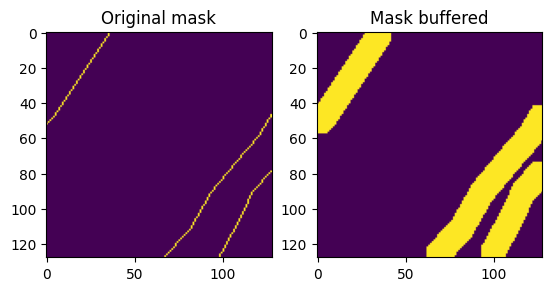

In [5]:
fig = plt.figure()

plt.subplot(1, 2, 1)
plt.imshow(mask)
plt.title("Original mask")

plt.subplot(1, 2, 2)
plt.imshow(mask_buffered)
plt.title("Mask buffered")

##Normalising Training Images

In [8]:
# Input / output directories
in_dir = '/content/drive/MyDrive/masters_final_folder/training_images'
out_dir = '/content/drive/MyDrive/masters_final_folder/normalised_training_images'
os.makedirs(out_dir, exist_ok=True)

# Step 1: Compute global DEM and slope min/max, and TPI percentiles
dem_vals, slope_vals, tpi_vals = [], [], []

for path in glob.glob(os.path.join(in_dir, "*.tif")):
    with rasterio.open(path) as src:
        dem_vals.append(src.read(1).ravel())
        slope_vals.append(src.read(2).ravel())
        tpi_vals.append(src.read(3).ravel())

dem_vals = np.concatenate(dem_vals)
slope_vals = np.concatenate(slope_vals)
tpi_vals = np.concatenate(tpi_vals)

# DEM and slope
dem_min, dem_max = dem_vals.min(), dem_vals.max()
slope_min, slope_max = slope_vals.min(), slope_vals.max()

# TPI: use 1st and 99th percentiles to clip outliers
p1, p99 = np.percentile(tpi_vals, [1, 99])

print("DEM min/max:", dem_min, dem_max)
print("Slope min/max:", slope_min, slope_max)
print("TPI 1st/99th percentiles:", p1, p99)

# Step 2: Normalize and write rasters
for fname in os.listdir(in_dir):
    if not fname.endswith(".tif"):
        continue

    in_path = os.path.join(in_dir, fname)
    out_path = os.path.join(out_dir, fname)

    with rasterio.open(in_path) as src:
        profile = src.profile
        profile.update(dtype="float32", nodata=None)

        dem = src.read(1)
        slope = src.read(2)
        tpi = src.read(3)

        # Normalize DEM and slope to [0,1]
        dem_n = (dem - dem_min) / (dem_max - dem_min)
        slope_n = (slope - slope_min) / (slope_max - slope_min)

        # Clip TPI to percentiles and scale to [-1,1]
        tpi_clip = np.clip(tpi, p1, p99)
        tpi_n = (tpi_clip - p1) / (p99 - p1)  # now in [0,1]
        tpi_n = tpi_n * 2 - 1                 # scale to [-1,1]

        # Stack channels
        stacked = np.stack([dem_n, slope_n, tpi_n]).astype("float32")

        # Write normalized raster
        with rasterio.open(out_path, "w", **profile) as dst:
            dst.write(stacked)

print("Normalization complete.")


DEM min/max: 6.31375 32.964375
Slope min/max: 0.0 42.466026
TPI 1st/99th percentiles: -0.07125091552734375 0.07062530517578125


Normalization complete.


In [9]:
sample_path = os.path.join(out_dir, "image_1.tif")

with rasterio.open(sample_path) as src:
    for i in range(1, 4):
        band = src.read(i)
        print(f"Band {i}: min {band.min():.3f}, max {band.max():.3f}, mean {band.mean():.3f}, std {band.std():.3f}")


Band 1: min 0.371, max 0.435, mean 0.404, std 0.012
Band 2: min 0.000, max 0.213, mean 0.043, std 0.028
Band 3: min -1.000, max 1.000, mean 0.004, std 0.301
